# HW: Linear Regression and Regression Trees

This notebook contains:

1. **Part 1 – Data generator**: `generate_noisy_dataset` creates synthetic `(x, f_1(x), ..., f_d(x), y)` data with uniform noise.
2. **Part 2 – Linear regression from scratch**: `fit` (normal equation), `predict`, `evaluate_model` (RMSE).
3. **Part 3 – Regression tree from scratch**: `RegressionTree` with `fit`, `predict`, `visualize`.
4. **Report experiments**

Only `numpy` and `matplotlib` are used for the models. `sklearn` is used only for `train_test_split`.

## Question 1: Repository

GitHub repository: [https://github.com/Maanav-1/hw2-DMT](https://github.com/Maanav-1/hw2-DMT)



## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# fixed seeds so every run produces the same data and the same train/test split
DATA_SEED = 0
SPLIT_SEED = 42

## Part 1: Data generator

`generate_noisy_dataset(funcs, true_f, x_range, n, eps)`:

- samples `n` values of `x` uniformly from `x_range`
- builds the input matrix `X = [x, f_1(x), ..., f_d(x)]` with shape `(n, d+1)` (rows = records, columns = attributes)
- computes the label `y = true_f(x) + noise`, with noise drawn uniformly from `[-eps, eps]`

The output `(X, y)` matches the format sklearn-style code expects.
We then split it **80% train / 20% test** with a fixed `random_state`, so repeated experiments on the same dataset use the same partition.

In [2]:
def make_features(x, funcs):
    # input attributes: x itself, followed by one column per extra function f_i(x)
    return np.column_stack([x] + [f(x) for f in funcs])


def generate_noisy_dataset(funcs, true_f, x_range, n, eps, seed=DATA_SEED):
    # funcs   : list of functions f_i(x) used to add columns (can be empty)
    # true_f  : the true function f(x) that generates y
    # x_range : (low, high) range to sample x from
    # n       : number of records
    # eps     : noise level; noise ~ Uniform[-eps, eps]
    rng = np.random.default_rng(seed)
    x = rng.uniform(x_range[0], x_range[1], n)
    X = make_features(x, funcs)
    y = true_f(x) + rng.uniform(-eps, eps, n)
    return X, y


def split(X, y):
    # fixed 80/20 partition (same random_state every time)
    return train_test_split(X, y, test_size=0.2, random_state=SPLIT_SEED)

Quick check using the example from the assignment: features `[x, x², x³]`, true function `log(x)`, 10 records, noise 0.1.

In [3]:
X_demo, y_demo = generate_noisy_dataset(
    funcs=[lambda x: x**2, lambda x: x**3],
    true_f=np.log, x_range=(1e-6, 1.0), n=10, eps=0.1)   # 1e-6 avoids log(0)

pd.DataFrame(np.column_stack([X_demo, y_demo]), columns=["x", "x^2", "x^3", "y"]).round(4)

,x,x^2,x^3,y
0,0.6370,0.4057,0.2584,-0.3879
1,0.2698,0.0728,0.0196,-1.4096
2,0.0410,0.0017,0.0001,-3.1233
3,0.0165,0.0003,0.0000,-4.1959
4,0.8133,0.6614,0.5379,-0.1608
5,0.9128,0.8331,0.7604,-0.1562
6,0.6066,0.3680,0.2232,-0.4272
7,0.7295,0.5322,0.3882,-0.3071
8,0.5436,0.2955,0.1607,-0.6496
9,0.9351,0.8744,0.8176,-0.0826


## Part 2: Linear regression

- **Training (`fit`)**: add a column of 1s at the front of `X` (so `β[0]` is the intercept), then solve the normal equation
  $\beta = (X^T X)^{-1} X^T Y$.
- **Prediction (`predict`)**: add the same column of 1s to the test data and compute $y_{pred} = X\beta$ for all rows at once.
- **Evaluation (`evaluate_model`)**: RMSE $= \sqrt{\frac{1}{n}\sum (y_{pred} - y_{true})^2}$.

Note: our data stores records as **rows** (shape `(n, d)`), so the 1s are added as a column with `np.column_stack`. The assignment's `np.vstack` hint is for data stored as columns.

In [4]:
def add_ones(X):
    # prepend a column of 1s -> the weight for this column is the intercept
    return np.column_stack([np.ones(len(X)), X])


def fit(X, y):
    # normal equation: beta = (X^T X)^-1 X^T y
    Xb = add_ones(X)
    return np.linalg.inv(Xb.T @ Xb) @ Xb.T @ y


def predict(beta, X):
    # y_pred = X . beta for every record
    return add_ones(X) @ beta


def evaluate_model(y_pred, y_true):
    # root mean square error
    return np.sqrt(np.mean((y_pred - y_true) ** 2))

Sanity check: our β should match numpy's least-squares solver.

In [5]:
X_chk, y_chk = generate_noisy_dataset([], lambda x: 2*x + 1, (0, 1), 1000, 0.1)
beta_ours = fit(X_chk, y_chk)
beta_np = np.linalg.lstsq(add_ones(X_chk), y_chk, rcond=None)[0]
print("ours :", beta_ours.round(6))
print("numpy:", beta_np.round(6))
print("match:", np.allclose(beta_ours, beta_np))

ours : [0.997255 1.99793 ]
numpy: [0.997255 1.99793 ]
match: True


## Part 3: Regression tree

`RegressionTree` builds a binary tree with recursive splits, following the tree-induction algorithm from the lecture, adapted for a continuous output:

- **Stopping rule (`is_leaf`)**: a node becomes a leaf if it has fewer than `min_records` records, or if all its y-values are equal. It also becomes a leaf if no split is possible (all x-values identical).
- **Leaf prediction**: the **mean** of the node's y-values.
- **Split candidates**: for each input column, sort the node's records by that column and try every **midpoint between consecutive distinct values** as threshold `t`.
- **Split score**: total squared error, `SSE(left) + SSE(right)` where left = `x ≤ t` and right = `x > t`. This equals minimizing variance. The lowest score wins.
- **Recursion**: split the records into the left and right subsets and build each child the same way.

Efficiency: SSE $= \sum y^2 - (\sum y)^2 / n$, so prefix sums (`np.cumsum`) score every split point of a column in one pass after sorting.

In [6]:
class Node:
    def __init__(self, feature=None, threshold=None, left=None, right=None, value=None, n=0):
        self.n = n                  # number of training records that reached this node
        self.feature = feature      # column index used for the split
        self.threshold = threshold  # records with x[feature] <= threshold go left
        self.left = left
        self.right = right
        self.value = value          # prediction (mean y), only set for leaves

    def is_leaf(self):
        return self.left is None


class RegressionTree:
    def __init__(self):
        self.root = None

    # ---------- training ----------
    def fit(self, dataset, min_records):
        X, y = dataset
        X = np.asarray(X, dtype=float)
        if X.ndim == 1:
            X = X.reshape(-1, 1)
        y = np.asarray(y, dtype=float)
        self.X_train, self.y_train = X, y      # kept for visualize()
        self.min_records = min_records
        self.root = self._build(X, y)
        return self

    def _build(self, X, y):
        # stop: too few records, or all outputs identical (pure node)
        if len(y) < self.min_records or np.all(y == y[0]):
            return Node(value=y.mean(), n=len(y))

        feature, threshold = self._best_split(X, y)
        if feature is None:                    # all x identical -> no split possible
            return Node(value=y.mean(), n=len(y))

        mask = X[:, feature] <= threshold      # True -> left child
        left = self._build(X[mask], y[mask])
        right = self._build(X[~mask], y[~mask])
        return Node(feature, threshold, left, right, n=len(y))

    def _best_split(self, X, y):
        # find the (column, threshold) with the lowest SSE(left) + SSE(right)
        n = len(y)
        best_sse, best_feature, best_threshold = np.inf, None, None

        for j in range(X.shape[1]):
            order = np.argsort(X[:, j])
            xs, ys = X[order, j], y[order]

            # prefix sums: left side of split position i = first i+1 sorted records
            csum, csum2 = np.cumsum(ys), np.cumsum(ys ** 2)
            n_left = np.arange(1, n)
            n_right = n - n_left
            s_left, s2_left = csum[:-1], csum2[:-1]
            s_right, s2_right = csum[-1] - s_left, csum2[-1] - s2_left

            # SSE = sum(y^2) - (sum y)^2 / n for each side
            sse = (s2_left - s_left ** 2 / n_left) + (s2_right - s_right ** 2 / n_right)

            # only allow thresholds between two different x-values
            valid = xs[:-1] < xs[1:]
            if not valid.any():
                continue
            sse = np.where(valid, sse, np.inf)

            i = np.argmin(sse)
            if sse[i] < best_sse:
                best_sse = sse[i]
                best_feature = j
                best_threshold = (xs[i] + xs[i + 1]) / 2   # midpoint

        return best_feature, best_threshold

    # ---------- prediction ----------
    def predict(self, X):
        X = np.asarray(X, dtype=float)
        if X.ndim == 1:
            X = X.reshape(-1, 1)
        return np.array([self._predict_one(row) for row in X])

    def _predict_one(self, row):
        # walk from the root to a leaf
        node = self.root
        while not node.is_leaf():
            node = node.left if row[node.feature] <= node.threshold else node.right
        return node.value

    # ---------- tree statistics ----------
    def _nodes(self, node=None):
        node = node or self.root
        if node.is_leaf():
            return [node]
        return [node] + self._nodes(node.left) + self._nodes(node.right)

    def n_nodes(self):
        return len(self._nodes())

    def leaf_sizes(self):
        # number of training records in each leaf
        return [nd.n for nd in self._nodes() if nd.is_leaf()]

    # ---------- visualization ----------
    def _split_points(self, node, out):
        if node.is_leaf():
            return
        out.append((node.feature, node.threshold))
        self._split_points(node.left, out)
        self._split_points(node.right, out)

    def visualize(self, true_f=None, title=None, ax=None, make_X=None, split_to_x=None):
        # make_X(grid)       : builds the input rows for a grid of x-values (default: x column only)
        # split_to_x(j, t)   : converts a threshold t on column j into an x-value for plotting
        #                      (e.g. a split x^2 <= t is the vertical line x = sqrt(t) for x >= 0)
        make_X = make_X or (lambda g: g.reshape(-1, 1))
        split_to_x = split_to_x or (lambda j, t: t)

        x, y = self.X_train[:, 0], self.y_train
        grid = np.linspace(x.min(), x.max(), 1000)
        splits = []
        self._split_points(self.root, splits)

        if ax is None:
            _, ax = plt.subplots(figsize=(9, 5))
        ax.scatter(x, y, s=6, color="gray", alpha=0.4, label="training data")
        alpha = 0.8 if len(splits) <= 50 else 0.15     # keep huge trees readable
        for i, (j, t) in enumerate(splits):
            ax.axvline(split_to_x(j, t), color="lightgray", linestyle="--", linewidth=0.8,
                       alpha=alpha, label="split points" if i == 0 else None)
        ax.plot(grid, self.predict(make_X(grid)), color="tab:blue", linewidth=1.5, label="tree prediction")
        if true_f is not None:
            ax.plot(grid, true_f(grid), color="tab:orange", linestyle="--", label="true f(x)")
        ax.set_xlabel("x")
        ax.set_ylabel("y")
        ax.set_title(title or f"Regression tree (min_records={self.min_records}, {len(splits)} splits)")
        ax.legend(fontsize=8)
        return ax

Quick demo of the tree on noisy `sin(2πx)` data (trained on the x column only):

tree test RMSE: 0.1968


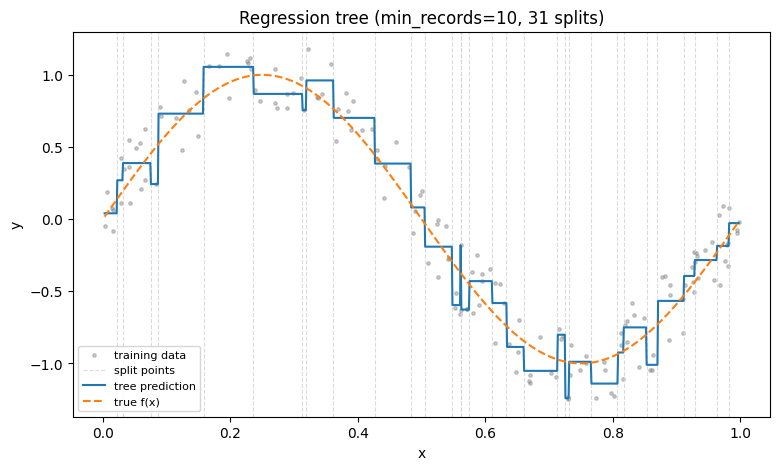

In [7]:
f_sin = lambda x: np.sin(2 * np.pi * x)
X_s, y_s = generate_noisy_dataset([], f_sin, (0, 1), 200, 0.3)
Xs_tr, Xs_te, ys_tr, ys_te = split(X_s, y_s)

tree = RegressionTree().fit((Xs_tr, ys_tr), min_records=10)
print("tree test RMSE:", round(evaluate_model(tree.predict(Xs_te), ys_te), 4))
tree.visualize(true_f=f_sin)
plt.show()

## Report experiments: shared setup

All combinations below use:
- x-range **[0, 1]**, **1000** records, 80/20 train/test split
- true functions: **Linear** `f(x) = 2x + 1` and **Cubic** `f(x) = 0.5x³ − x² + x`
- noise levels **0.01** and **0.1**

`run_experiments(funcs)` trains, tests, and plots every combination for one choice of input columns.
Each plot shows the training data (scatter), the true function, and the **entire** learned linear model over the x-range (for the x² and x³ columns, this means $\beta_0 + \beta_1 x + \beta_2 x^2 + \beta_3 x^3$).

In [8]:
TRUE_FUNCS = {
    "Linear: 2x + 1": lambda x: 2 * x + 1,
    "Cubic: 0.5x³ − x² + x": lambda x: 0.5 * x**3 - x**2 + x,
}
NOISE_LEVELS = [0.01, 0.1]
N, X_RANGE = 1000, (0.0, 1.0)

EXTRA_NONE = []                                   # input = (x)
EXTRA_POLY = [lambda x: x**2, lambda x: x**3]     # input = (x, x^2, x^3)


def get_split_dataset(fname, eps, funcs):
    # one fixed seed per (true function, noise) combination
    # -> every experiment (LR with/without extra columns, trees) sees the exact same x, noise and split
    r = list(TRUE_FUNCS).index(fname)
    c = NOISE_LEVELS.index(eps)
    X, y = generate_noisy_dataset(funcs, TRUE_FUNCS[fname], X_RANGE, N, eps, seed=10 * r + c)
    return split(X, y)


def run_experiments(funcs, label):
    # train/test/plot linear regression for every (true function, noise) combination
    results, models = [], {}
    fig, axes = plt.subplots(2, 2, figsize=(13, 9))
    grid = np.linspace(*X_RANGE, 500)

    for r, (fname, true_f) in enumerate(TRUE_FUNCS.items()):
        for c, eps in enumerate(NOISE_LEVELS):
            X_tr, X_te, y_tr, y_te = get_split_dataset(fname, eps, funcs)

            beta = fit(X_tr, y_tr)
            train_rmse = evaluate_model(predict(beta, X_tr), y_tr)
            test_rmse = evaluate_model(predict(beta, X_te), y_te)
            models[(fname, eps)] = beta

            # plot: training scatter + true function + full linear model on a dense grid
            ax = axes[r, c]
            ax.scatter(X_tr[:, 0], y_tr, s=6, color="gray", alpha=0.4, label="training data")
            ax.plot(grid, true_f(grid), color="tab:orange", linewidth=2, label="true f(x)")
            ax.plot(grid, predict(beta, make_features(grid, funcs)), color="tab:blue",
                    linestyle="--", linewidth=2, label="linear model")
            ax.set_title(f"{fname}, noise={eps}\ntest RMSE={test_rmse:.4f}")
            ax.set_xlabel("x"); ax.set_ylabel("y"); ax.legend()

            results.append({"true function": fname, "noise": eps,
                            "coefficients β": np.round(beta, 4).tolist(),
                            "train RMSE": round(train_rmse, 5), "test RMSE": round(test_rmse, 5)})

    fig.suptitle(f"Linear regression, input columns: {label}", fontsize=14)
    plt.tight_layout()
    plt.show()
    return pd.DataFrame(results), models

## Question 3: Linear regression with input columns (x, y)

The list of extra functions is empty, so the model is a straight line $\beta_0 + \beta_1 x$.

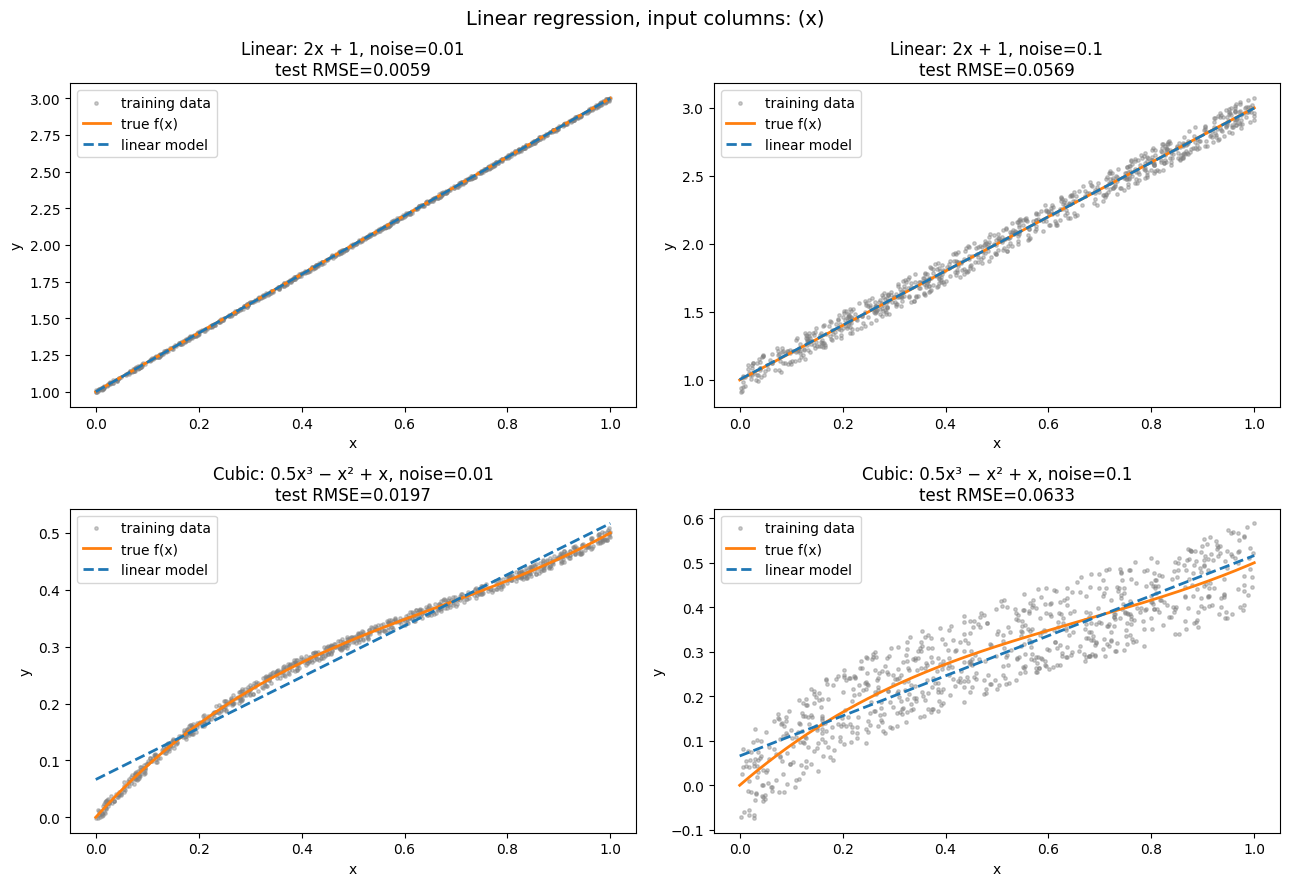

,true function,noise,coefficients β,train RMSE,test RMSE
0,Linear: 2x + 1,0.01,"[0.9999, 1.9996]",0.00592,0.00589
1,Linear: 2x + 1,0.10,"[1.003, 1.995]",0.05676,0.05689
2,Cubic: 0.5x³ − x² + x,0.01,"[0.0664, 0.4504]",0.02261,0.01969
3,Cubic: 0.5x³ − x² + x,0.10,"[0.0658, 0.4503]",0.05976,0.06333


In [9]:
res_q3, models_q3 = run_experiments(EXTRA_NONE, "(x)")
res_q3

**Findings (Q3):**
- **Linear true function:** the line recovers the true coefficients almost exactly (β ≈ [1.00, 2.00]). Test RMSE ≈ 0.0059 for noise 0.01 and ≈ 0.057 for noise 0.1. That is the noise floor: uniform noise on [−ε, ε] has standard deviation ε/√3 (0.0058 and 0.058), so no model could do better.
- **Cubic true function:** a straight line can't follow the curve. At noise 0.01 the test RMSE (≈ 0.020) is about 3× the noise floor (0.0058). The extra error comes from the model being too simple (underfitting), not from noise. At noise 0.1 this gap is mostly hidden by the noise (≈ 0.063 vs 0.058), but the line still systematically misses the curvature, as the plot shows.

## Question 4: Linear regression with input columns (x, x², x³, y)

Same experiments, but with the extra columns $f_1(x)=x^2$ and $f_2(x)=x^3$.
The model is still linear in its weights, but as a function of x it is a cubic polynomial $\beta_0 + \beta_1 x + \beta_2 x^2 + \beta_3 x^3$.

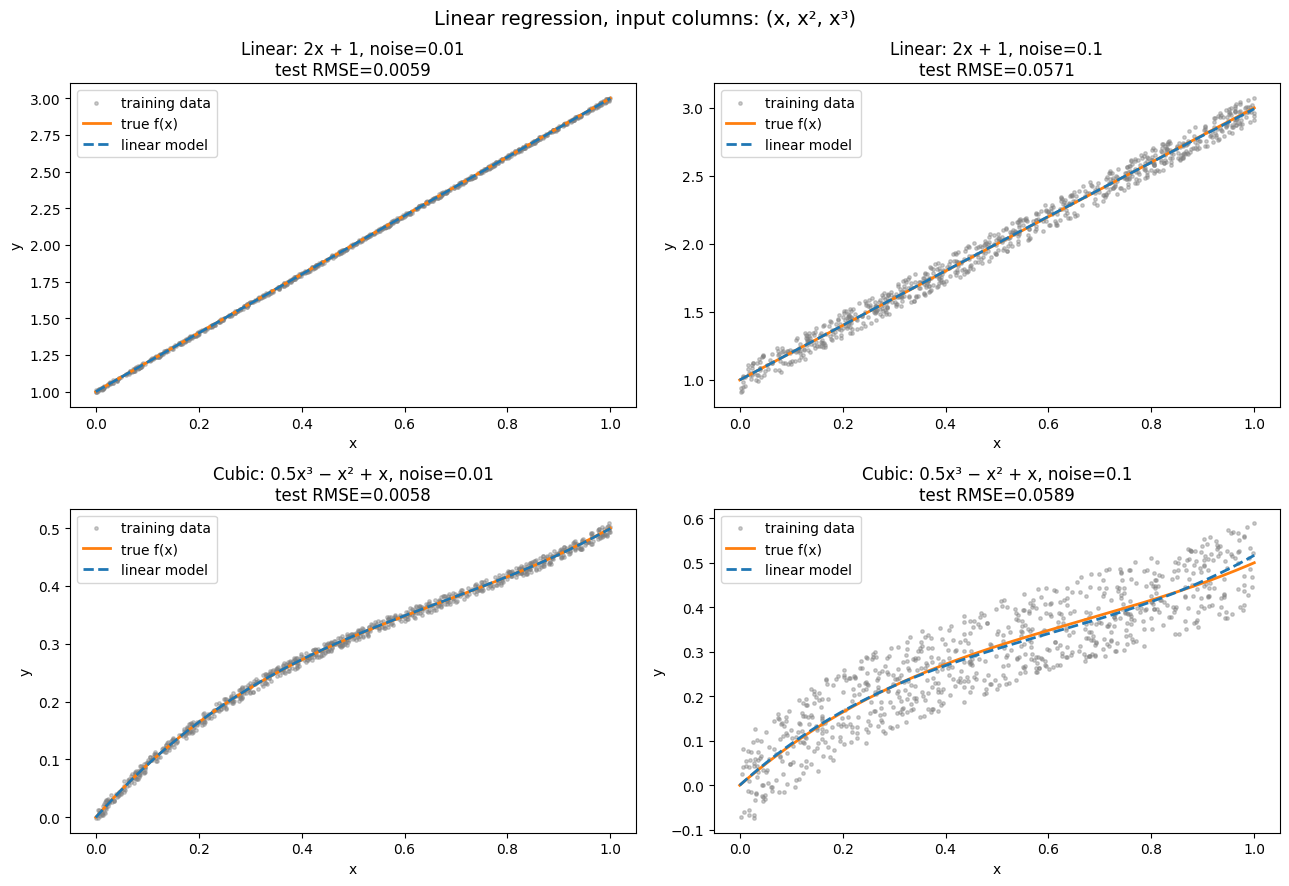

,true function,noise,coefficients β,train RMSE,test RMSE
0,Linear: 2x + 1,0.01,"[1.0, 1.9962, 0.0103, -0.0077]",0.00592,0.00589
1,Linear: 2x + 1,0.10,"[0.9997, 2.0069, 0.0101, -0.0238]",0.05673,0.05707
2,Cubic: 0.5x³ − x² + x,0.01,"[-0.0003, 1.0034, -1.003, 0.4993]",0.00593,0.00576
3,Cubic: 0.5x³ − x² + x,0.10,"[0.0, 1.041, -1.1868, 0.6625]",0.05664,0.05894


In [10]:
res_q4, models_q4 = run_experiments(EXTRA_POLY, "(x, x², x³)")
res_q4

In [11]:
# side-by-side test RMSE: do the extra columns help?
compare = res_q3[["true function", "noise"]].copy()
compare["test RMSE (x)"] = res_q3["test RMSE"]
compare["test RMSE (x, x², x³)"] = res_q4["test RMSE"]
compare

,true function,noise,test RMSE (x),"test RMSE (x, x², x³)"
0,Linear: 2x + 1,0.01,0.00589,0.00589
1,Linear: 2x + 1,0.10,0.05689,0.05707
2,Cubic: 0.5x³ − x² + x,0.01,0.01969,0.00576
3,Cubic: 0.5x³ − x² + x,0.10,0.06333,0.05894


**Findings (Q4): do the extra columns help?**
- **Cubic true function: yes.** The model can now represent the true function exactly. At noise 0.01 it recovers β ≈ [0, 1, −1, 0.5], the true coefficients, and the test RMSE drops from ≈ 0.020 to the noise floor ≈ 0.0058. At noise 0.1 the RMSE also improves (0.063 → 0.059). The coefficients are less exact (≈ [0, 1.04, −1.19, 0.66]) because the noise makes the x, x², x³ weights trade off against each other, but the curve on [0, 1] still matches the true function closely.
- **Linear true function: no.** The extra weights come out close to 0, and the test RMSE is unchanged (noise 0.01) or slightly worse (noise 0.1: 0.0569 → 0.0571). This is because the model fits a little noise with terms it doesn't need.
- **Conclusion:** extra columns help when the true function needs them. Otherwise they add nothing on the training range and can slightly hurt.

## Question 5: Prediction error at (x, y) = (10, f(10))

x = 10 lies far **outside** the training range [0, 1], so this tests **extrapolation**.
For each model we predict at x = 10 and compare with the exact (noise-free) value f(10).
Error = prediction − f(10).

In [12]:
def extrapolation_table(models, funcs, label, x0=10.0):
    rows = []
    for (fname, eps), beta in models.items():
        y_true = TRUE_FUNCS[fname](x0)
        y_pred = predict(beta, make_features(np.array([x0]), funcs))[0]
        rows.append({"input columns": label, "true function": fname, "noise": eps,
                     "f(10)": round(y_true, 4), "prediction": round(y_pred, 4),
                     "error": round(y_pred - y_true, 4),
                     "relative error": f"{abs(y_pred - y_true) / abs(y_true):.2%}"})
    return rows

res_q5 = pd.DataFrame(extrapolation_table(models_q3, EXTRA_NONE, "(x)")
                      + extrapolation_table(models_q4, EXTRA_POLY, "(x, x², x³)"))
res_q5

,input columns,true function,noise,f(10),prediction,error,relative error
0,(x),Linear: 2x + 1,0.01,21.0,20.9956,-0.0044,0.02%
1,(x),Linear: 2x + 1,0.10,21.0,20.9532,-0.0468,0.22%
2,(x),Cubic: 0.5x³ − x² + x,0.01,410.0,4.5707,-405.4293,98.89%
3,(x),Cubic: 0.5x³ − x² + x,0.10,410.0,4.5693,-405.4307,98.89%
4,"(x, x², x³)",Linear: 2x + 1,0.01,21.0,14.2991,-6.7009,31.91%
5,"(x, x², x³)",Linear: 2x + 1,0.10,21.0,-1.7146,-22.7146,108.16%
6,"(x, x², x³)",Cubic: 0.5x³ − x² + x,0.01,410.0,408.9993,-1.0007,0.24%
7,"(x, x², x³)",Cubic: 0.5x³ − x² + x,0.10,410.0,554.1957,144.1957,35.17%


**Findings (Q5): when is the prediction at x = 10 "good"?**

The prediction is good in only two cases:
- **Line on the linear function:** error ≈ −0.004 (noise 0.01) and ≈ −0.05 (noise 0.1), well under 1%. The model has the right form, so extrapolation works.
- **Cubic model on the cubic function, noise 0.01:** error ≈ −1.0 out of 410 (0.24%).

It is bad in the other cases:
- **Line on the cubic function:** it predicts ≈ 4.6 instead of 410 (≈ 99% off). The model has the wrong form, so it fails completely outside [0, 1].
- **Cubic model on the linear function:** the true x² and x³ weights are 0, but the fitted ones are small non-zero values (e.g., −0.008 or −0.024 for x³). At x = 10 they get multiplied by 100 and 1000, giving errors of ≈ 32% and ≈ 108%.
- **Cubic model on the cubic function, noise 0.1:** the coefficient errors from the noise get amplified the same way, giving ≈ 35% error.

**Takeaway:** a model fit on [0, 1] predicts well far outside that range only if its form matches the true function and the noise is low. High-degree terms magnify small coefficient errors, so a polynomial that fits well on the training range can extrapolate badly. Low test RMSE on [0, 1] (Q4) does not guarantee good extrapolation (Q5).

## Question 6: Analysis of the linear-regression experiments

### Bias–variance background
For data generated as $y = f(x) + \varepsilon$ with noise of mean 0, the **optimal model** (the one with the lowest possible expected squared error) is the conditional mean $E[y \mid x] = f(x)$, i.e. **the true function itself**. Any other model adds bias and/or variance on top of the noise.

The **irreducible error** is the error that even the optimal model makes, because the noise can't be predicted. Noise is uniform on $[-\varepsilon, \varepsilon]$, so its variance is $\varepsilon^2 / 3$, and the irreducible **RMSE** is

$$\text{RMSE}_{irr} = \sqrt{E[\text{noise}^2]} = \frac{\varepsilon}{\sqrt{3}} \approx 0.00577 \ (\varepsilon = 0.01), \quad 0.0577 \ (\varepsilon = 0.1).$$

We also measure it empirically: the RMSE of the true function f on each test set.

In [13]:
rows = []
for fname, true_f in TRUE_FUNCS.items():
    for eps in NOISE_LEVELS:
        _, X_te, _, y_te = get_split_dataset(fname, eps, EXTRA_NONE)
        rows.append({"true function": fname, "noise": eps,
                     "irreducible RMSE (ε/√3)": round(eps / np.sqrt(3), 5),
                     "optimal model f(x), test RMSE": round(evaluate_model(true_f(X_te[:, 0]), y_te), 5)})
irr = pd.DataFrame(rows)

# add the learned models' test RMSE for comparison
irr["LR (x), test RMSE"] = res_q3["test RMSE"].values
irr["LR (x, x², x³), test RMSE"] = res_q4["test RMSE"].values
irr

,true function,noise,irreducible RMSE (ε/√3),"optimal model f(x), test RMSE","LR (x), test RMSE","LR (x, x², x³), test RMSE"
0,Linear: 2x + 1,0.01,0.00577,0.00590,0.00589,0.00589
1,Linear: 2x + 1,0.10,0.05774,0.05699,0.05689,0.05707
2,Cubic: 0.5x³ − x² + x,0.01,0.00577,0.00575,0.01969,0.00576
3,Cubic: 0.5x³ − x² + x,0.10,0.05774,0.05860,0.06333,0.05894


In [14]:
# learned coefficients vs. the optimal model's coefficients [β0, β1, β2, β3]
optimal = {"Linear: 2x + 1": [1, 2, 0, 0], "Cubic: 0.5x³ − x² + x": [0, 1, -1, 0.5]}
coef = res_q4[["true function", "noise"]].copy()
coef["optimal β"] = coef["true function"].map(optimal)
coef["learned β (x)"] = res_q3["coefficients β"]
coef["learned β (x, x², x³)"] = res_q4["coefficients β"]
coef

,true function,noise,optimal β,learned β (x),"learned β (x, x², x³)"
0,Linear: 2x + 1,0.01,"[1, 2, 0, 0]","[0.9999, 1.9996]","[1.0, 1.9962, 0.0103, -0.0077]"
1,Linear: 2x + 1,0.10,"[1, 2, 0, 0]","[1.003, 1.995]","[0.9997, 2.0069, 0.0101, -0.0238]"
2,Cubic: 0.5x³ − x² + x,0.01,"[0, 1, -1, 0.5]","[0.0664, 0.4504]","[-0.0003, 1.0034, -1.003, 0.4993]"
3,Cubic: 0.5x³ − x² + x,0.10,"[0, 1, -1, 0.5]","[0.0658, 0.4503]","[0.0, 1.041, -1.1868, 0.6625]"


**Findings (Q6):**

**a.** The models predict well for the **linear** function in every setup: both schemas reach the irreducible error. For the **cubic** function, only the (x, x², x³) model predicts well. The plain line underfits it, and at noise 0.01 its test RMSE is about 3× the irreducible error.

**b.** The optimal model is the true function $f(x) = E[y \mid x]$.
- **Linear:** the optimal model is $1 + 2x$. Both learned models come very close: the line gets β ≈ [1.00, 2.00], and the polynomial model also gets ≈ [1, 2] with near-zero x², x³ weights.
- **Cubic:** the optimal model is $x - x^2 + 0.5x^3$. The line *cannot* represent it, so it stays far from optimal. The (x, x², x³) model can: at noise 0.01 it recovers ≈ [0, 1.00, −1.00, 0.50], almost exactly optimal. At noise 0.1 the coefficients are noticeably off (≈ [0, 1.04, −1.19, 0.66]), but the resulting curve on [0, 1] is still very close to f.

**c.** The irreducible error is the RMSE of the optimal model, $\varepsilon/\sqrt{3}$: **0.0058** for noise 0.01 and **0.058** for noise 0.1. The empirical value (the true f evaluated on each test set) matches this closely. Every model that has the right form gets within about 1–2% of it on the test data: both models for the linear function, and the (x, x², x³) model for the cubic. The line on the cubic function does not (≈ 0.020 vs 0.0058 at noise 0.01). At noise 0.1 it looks closer (≈ 0.063 vs 0.058) only because the noise dominates its bias.

## Question 7: Adding higher-order monomials (cubic, noise 0.1)

Schemas $(x), (x, x^2), \dots, (x, x^2, \dots, x^{10})$ on the same 1000-point cubic dataset with noise 0.1.

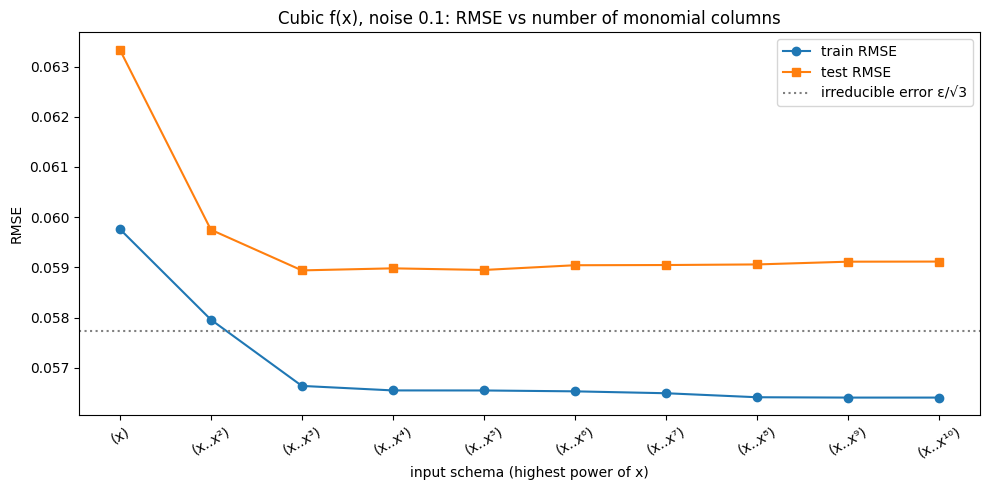

,schema,train RMSE,test RMSE
0,(x),0.05976,0.06333
1,(x..x²),0.05796,0.05975
2,(x..x³),0.05664,0.05894
3,(x..x⁴),0.05655,0.05898
4,(x..x⁵),0.05655,0.05895
5,(x..x⁶),0.05653,0.05904
6,(x..x⁷),0.05649,0.05905
7,(x..x⁸),0.05641,0.05906
8,(x..x⁹),0.05641,0.05911
9,(x..x¹⁰),0.05641,0.05912


In [15]:
fname, eps = "Cubic: 0.5x³ − x² + x", 0.1
degrees = list(range(1, 11))
train_err, test_err = [], []

for d in degrees:
    funcs = [lambda x, k=k: x**k for k in range(2, d + 1)]   # x^2 ... x^d  (k=k binds the exponent)
    X_tr, X_te, y_tr, y_te = get_split_dataset(fname, eps, funcs)
    beta = fit(X_tr, y_tr)
    train_err.append(evaluate_model(predict(beta, X_tr), y_tr))
    test_err.append(evaluate_model(predict(beta, X_te), y_te))

labels = ["(x)"] + [f"(x..x{''.join('⁰¹²³⁴⁵⁶⁷⁸⁹'[int(c)] for c in str(d))})" for d in degrees[1:]]
plt.figure(figsize=(10, 5))
plt.plot(degrees, train_err, "o-", label="train RMSE")
plt.plot(degrees, test_err, "s-", label="test RMSE")
plt.axhline(eps / np.sqrt(3), color="gray", linestyle=":", label="irreducible error ε/√3")
plt.xticks(degrees, labels, rotation=30)
plt.xlabel("input schema (highest power of x)")
plt.ylabel("RMSE")
plt.title("Cubic f(x), noise 0.1: RMSE vs number of monomial columns")
plt.legend()
plt.tight_layout()
plt.show()

pd.DataFrame({"schema": labels, "train RMSE": np.round(train_err, 5), "test RMSE": np.round(test_err, 5)})

**Findings (Q7):** Training RMSE **only goes down** as columns are added (0.0598 → 0.0564). Each schema contains the previous one, so the fit on the training data can never get worse. Test RMSE drops sharply up to (x, x², x³) (0.0633 → 0.0589), which is the true degree and lands close to the irreducible error (0.0577). After that it stays flat or creeps up slightly (→ 0.0591), while training RMSE keeps falling *below* the irreducible error. The extra columns beyond x³ only fit noise. The growing gap between training and test error is the start of overfitting. It stays mild here because 800 training points on a smooth function leave little room to overfit, but more columns never help on unseen data once the true form is covered.

## Tree experiments [16 points]

Same training and test sets as for linear regression: true functions [linear, cubic] × noise [0.01, 0.1] × schemas [(x), (x, x², x³)] × `min_records` [1000, 50, 1].

For the (x, x², x³) schema, the tree may split on x² or x³. Since x ≥ 0, a split $x^k \le t$ is the same as $x \le t^{1/k}$, so we draw it as a vertical line at $t^{1/k}$.

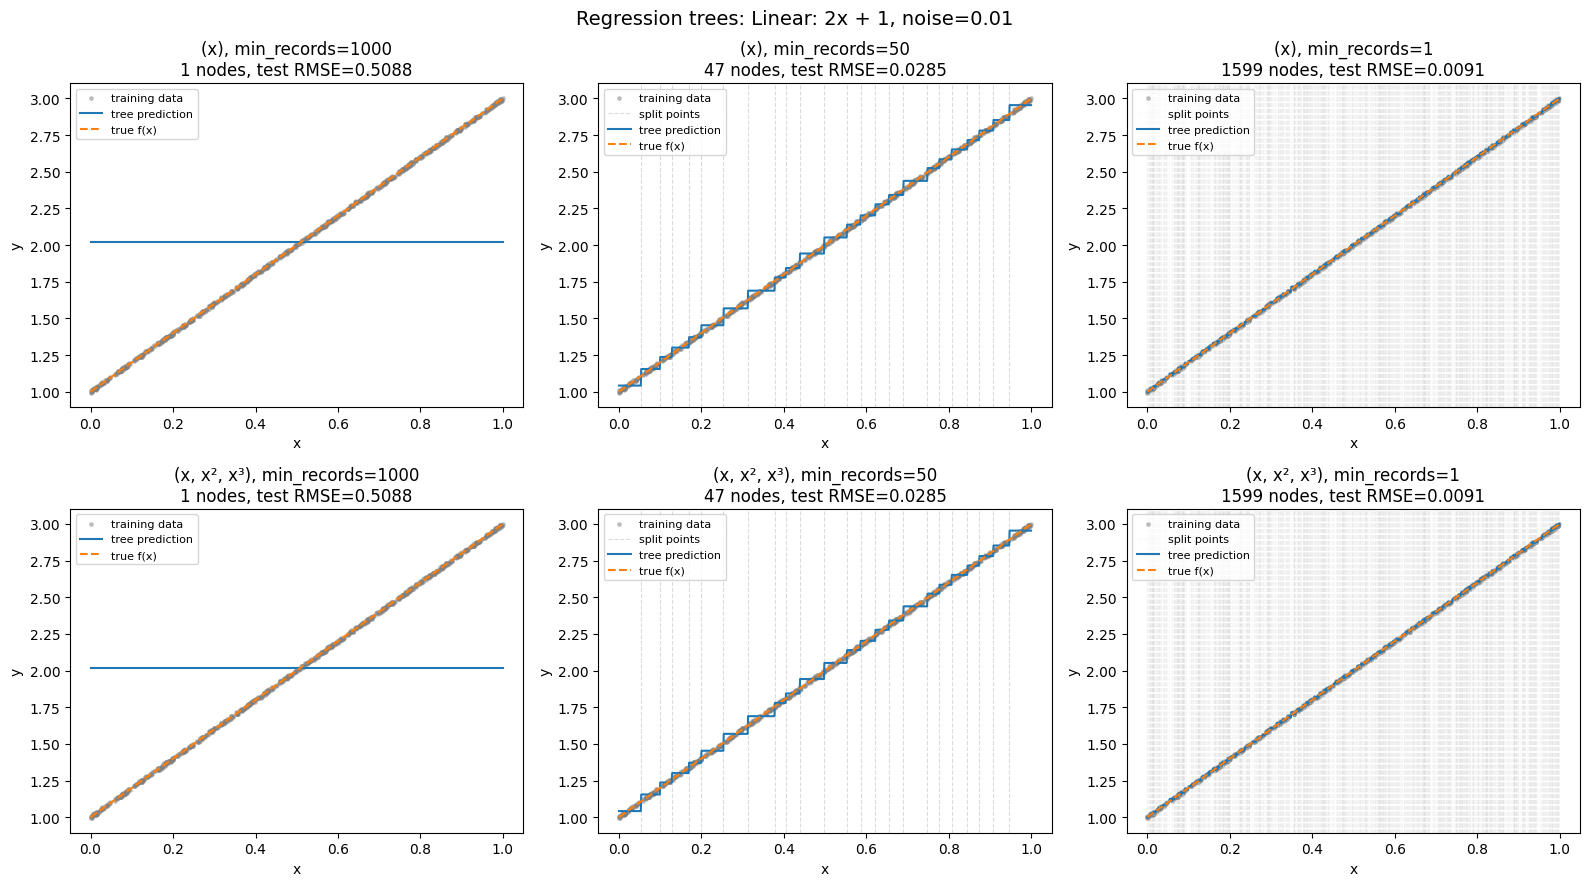

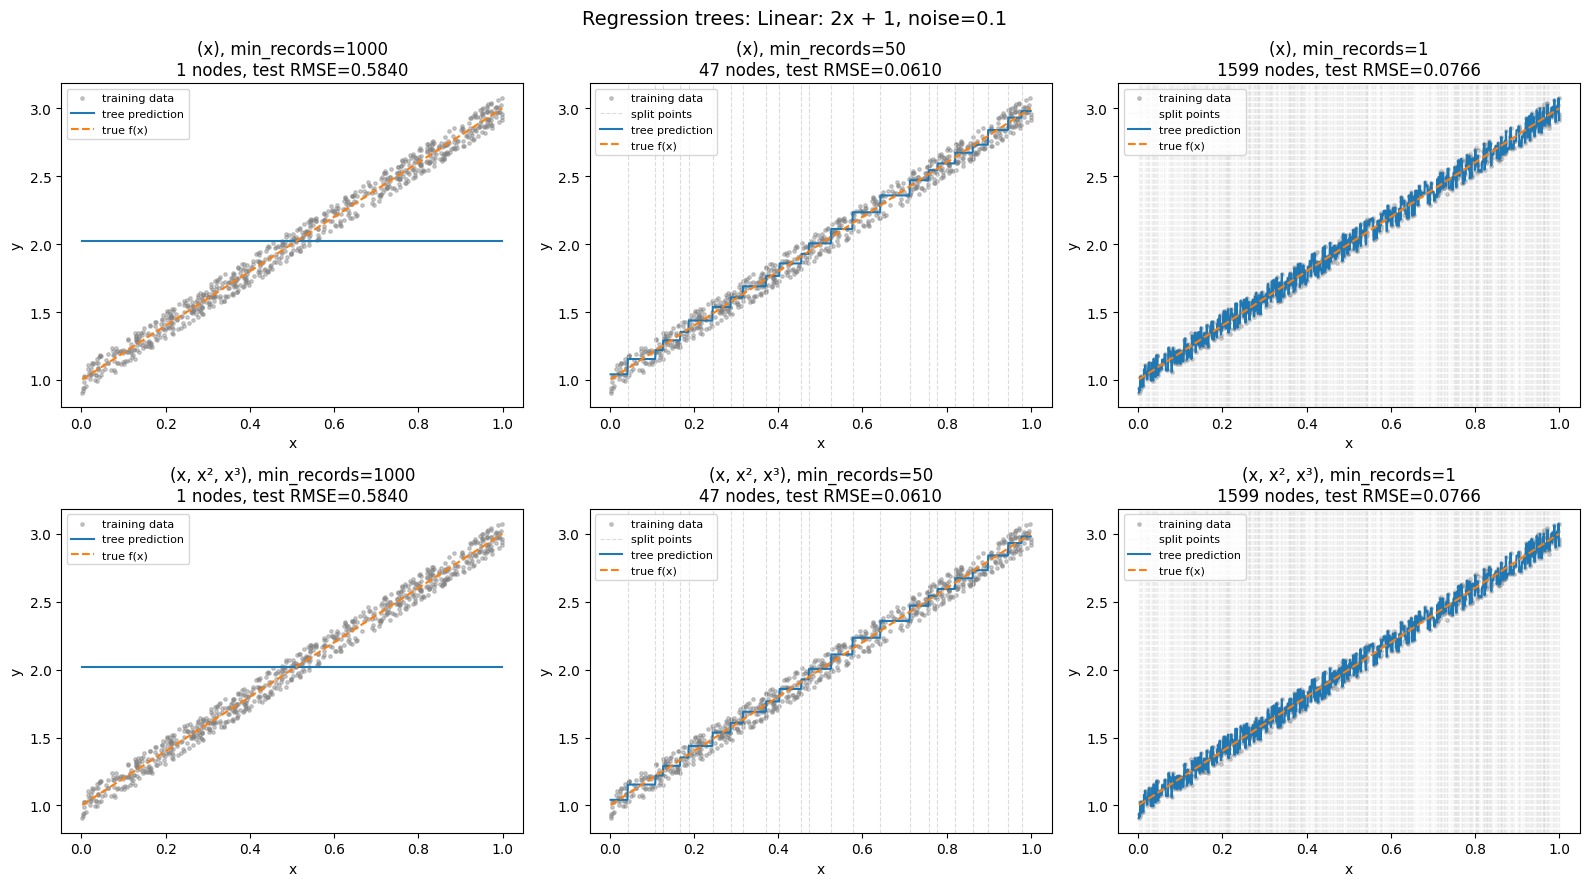

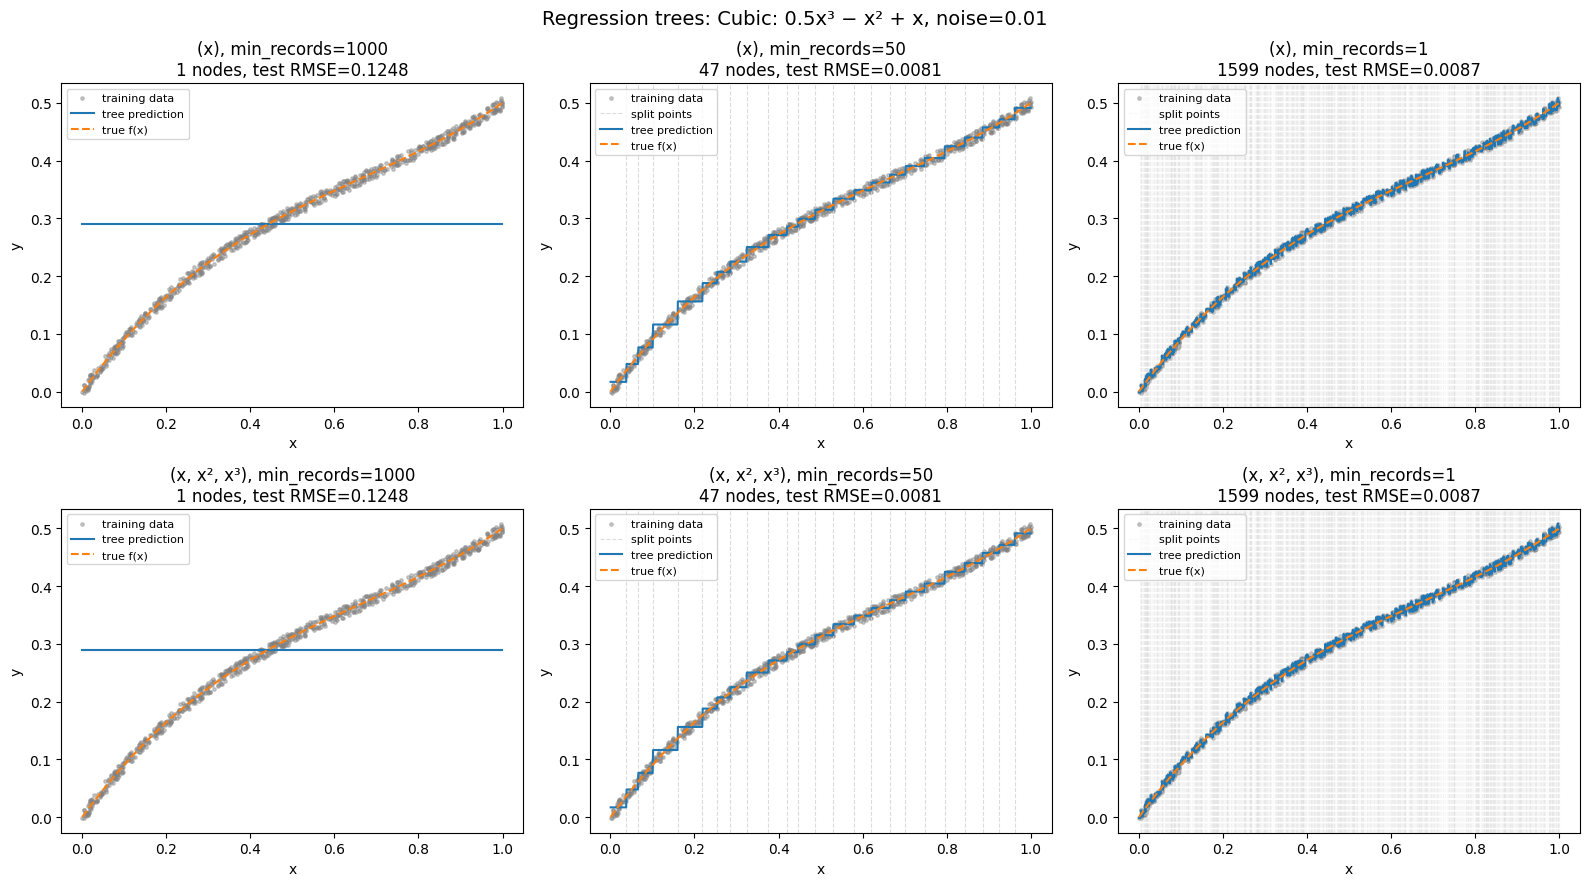

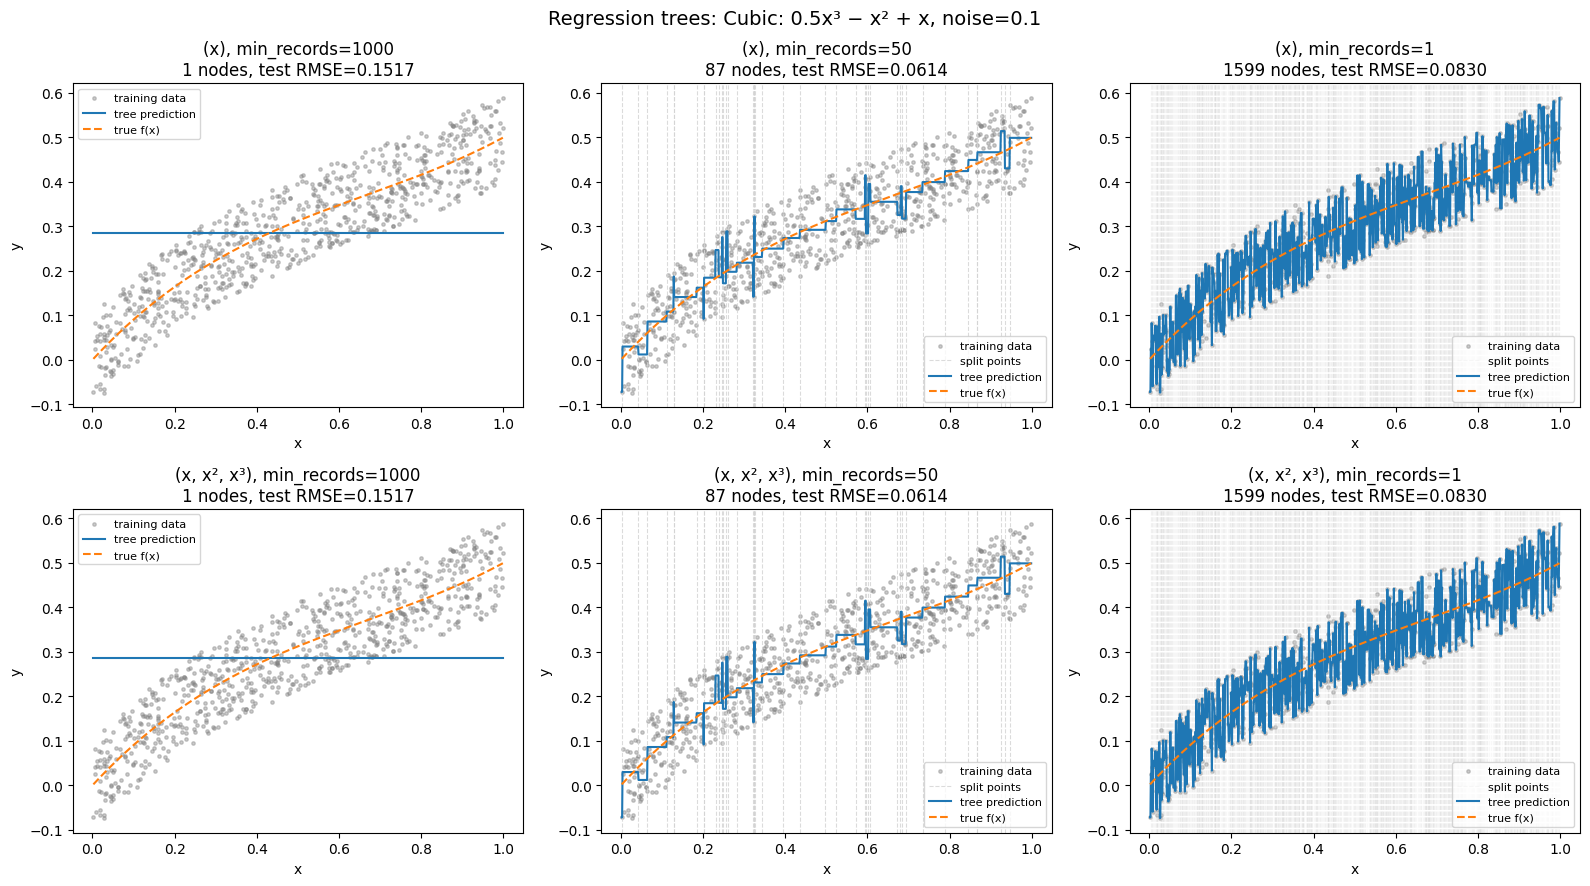

,true function,noise,schema,min_records,nodes,leaves,records/leaf (min/mean/max),train RMSE,test RMSE
0,Linear: 2x + 1,0.01,(x),1000,1,1,800/800.0/800,0.58348,0.50882
1,Linear: 2x + 1,0.01,(x),50,47,24,21/33.3/47,0.02437,0.02846
2,Linear: 2x + 1,0.01,(x),1,1599,800,1/1.0/1,0.00000,0.00910
3,Linear: 2x + 1,0.01,"(x, x², x³)",1000,1,1,800/800.0/800,0.58348,0.50882
4,Linear: 2x + 1,0.01,"(x, x², x³)",50,47,24,21/33.3/47,0.02437,0.02846
5,Linear: 2x + 1,0.01,"(x, x², x³)",1,1599,800,1/1.0/1,0.00000,0.00910
6,Linear: 2x + 1,0.10,(x),1000,1,1,800/800.0/800,0.57955,0.58396
7,Linear: 2x + 1,0.10,(x),50,47,24,11/33.3/49,0.05573,0.06098
8,Linear: 2x + 1,0.10,(x),1,1599,800,1/1.0/1,0.00000,0.07664
9,Linear: 2x + 1,0.10,"(x, x², x³)",1000,1,1,800/800.0/800,0.57955,0.58396


In [16]:
MIN_RECORDS = [1000, 50, 1]
SCHEMAS = {"(x)": EXTRA_NONE, "(x, x², x³)": EXTRA_POLY}

# convert a split on column j (= x^(j+1)) back into an x-value for plotting
poly_split_to_x = lambda j, t: np.sign(t) * abs(t) ** (1 / (j + 1))

tree_rows = []
for fname, true_f in TRUE_FUNCS.items():
    for eps in NOISE_LEVELS:
        fig, axes = plt.subplots(2, 3, figsize=(16, 9))
        for r, (sname, funcs) in enumerate(SCHEMAS.items()):
            X_tr, X_te, y_tr, y_te = get_split_dataset(fname, eps, funcs)
            for c, mr in enumerate(MIN_RECORDS):
                tree = RegressionTree().fit((X_tr, y_tr), min_records=mr)
                train_rmse = evaluate_model(tree.predict(X_tr), y_tr)
                test_rmse = evaluate_model(tree.predict(X_te), y_te)
                leaves = tree.leaf_sizes()

                tree.visualize(true_f=true_f, ax=axes[r, c],
                               make_X=lambda g, funcs=funcs: make_features(g, funcs),
                               split_to_x=poly_split_to_x,
                               title=f"{sname}, min_records={mr}\n"
                                     f"{tree.n_nodes()} nodes, test RMSE={test_rmse:.4f}")

                tree_rows.append({"true function": fname, "noise": eps, "schema": sname,
                                  "min_records": mr, "nodes": tree.n_nodes(), "leaves": len(leaves),
                                  "records/leaf (min/mean/max)": f"{min(leaves)}/{np.mean(leaves):.1f}/{max(leaves)}",
                                  "train RMSE": round(train_rmse, 5), "test RMSE": round(test_rmse, 5)})
        fig.suptitle(f"Regression trees: {fname}, noise={eps}", fontsize=14)
        plt.tight_layout()
        plt.show()

res_tree = pd.DataFrame(tree_rows)
res_tree

## Question 10: Trees vs. linear models

In [17]:
# test RMSE of every tree next to the linear model trained on the same input data
lr_rmse = {}
for (res, sname) in [(res_q3, "(x)"), (res_q4, "(x, x², x³)")]:
    for _, row in res.iterrows():
        lr_rmse[(row["true function"], row["noise"], sname)] = row["test RMSE"]

cmp = res_tree.pivot_table(index=["true function", "noise", "schema"],
                           columns="min_records", values="test RMSE")
cmp.columns = [f"tree mr={c}" for c in cmp.columns]
cmp = cmp[["tree mr=1000", "tree mr=50", "tree mr=1"]]
cmp["linear model"] = [lr_rmse[i] for i in cmp.index]
cmp["irreducible ε/√3"] = [round(i[1] / np.sqrt(3), 5) for i in cmp.index]
cmp["winner"] = cmp[["tree mr=1000", "tree mr=50", "tree mr=1", "linear model"]].idxmin(axis=1)
cmp

tree mr=1000  tree mr=50  tree mr=1  \
true function         noise schema                                             
Cubic: 0.5x³ − x² + x 0.01  (x)               0.12476     0.00812    0.00869   
                            (x, x², x³)       0.12476     0.00812    0.00869   
                      0.10  (x)               0.15169     0.06137    0.08299   
                            (x, x², x³)       0.15169     0.06137    0.08299   
Linear: 2x + 1        0.01  (x)               0.50882     0.02846    0.00910   
                            (x, x², x³)       0.50882     0.02846    0.00910   
                      0.10  (x)               0.58396     0.06098    0.07664   
                            (x, x², x³)       0.58396     0.06098    0.07664   

                                         linear model  irreducible ε/√3  \
true function         noise schema                                        
Cubic: 0.5x³ − x² + x 0.01  (x)               0.01969           0.00577   
                            (x, x², x³)       0.00576           0.00577   
                      0.10  (x)               0.06333           0.05774   
                            (x, x², x³)       0.05894           0.05774   
Linear: 2x + 1        0.01  (x)               0.00589           0.00577   
                            (x, x², x³)       0.00589           0.00577   
                      0.10  (x)               0.05689           0.05774   
                            (x, x², x³)       0.05707           0.05774   

                                               winner  
true function         noise schema                     
Cubic: 0.5x³ − x² + x 0.01  (x)            tree mr=50  
                            (x, x², x³)  linear model  
                      0.10  (x)            tree mr=50  
                            (x, x², x³)  linear model  
Linear: 2x + 1        0.01  (x)          linear model  
                            (x, x², x³)  linear model  
                      0.10  (x)          linear model  
                            (x, x², x³)  linear model

In [18]:
# (i) do extra columns change the tree at all? compare predictions on the same test x-values
for fname in TRUE_FUNCS:
    for eps in NOISE_LEVELS:
        for mr in MIN_RECORDS:
            _, Xa_te, _, _ = get_split_dataset(fname, eps, EXTRA_NONE)
            Xa_tr, _, ya_tr, _ = get_split_dataset(fname, eps, EXTRA_NONE)
            Xb_tr, Xb_te, yb_tr, _ = get_split_dataset(fname, eps, EXTRA_POLY)
            pa = RegressionTree().fit((Xa_tr, ya_tr), mr).predict(Xa_te)
            pb = RegressionTree().fit((Xb_tr, yb_tr), mr).predict(Xb_te)
            print(f"{fname:24s} noise={eps:<5} min_records={mr:<5} identical predictions: {np.allclose(pa, pb)}")

Linear: 2x + 1           noise=0.01  min_records=1000  identical predictions: True
Linear: 2x + 1           noise=0.01  min_records=50    identical predictions: True
Linear: 2x + 1           noise=0.01  min_records=1     identical predictions: True
Linear: 2x + 1           noise=0.1   min_records=1000  identical predictions: True
Linear: 2x + 1           noise=0.1   min_records=50    identical predictions: True
Linear: 2x + 1           noise=0.1   min_records=1     identical predictions: True
Cubic: 0.5x³ − x² + x    noise=0.01  min_records=1000  identical predictions: True
Cubic: 0.5x³ − x² + x    noise=0.01  min_records=50    identical predictions: True
Cubic: 0.5x³ − x² + x    noise=0.01  min_records=1     identical predictions: True
Cubic: 0.5x³ − x² + x    noise=0.1   min_records=1000  identical predictions: True
Cubic: 0.5x³ − x² + x    noise=0.1   min_records=50    identical predictions: True
Cubic: 0.5x³ − x² + x    noise=0.1   min_records=1     identical predictions: True


**Findings (Q10):** **Who wins?** The **linear model** wins whenever it has the right form: the linear function with either schema, and the cubic function with (x, x², x³). In those cases it sits at the irreducible error. The **tree with min_records=50 wins only for the cubic function with schema (x)**, where the straight line underfits (0.0081 vs 0.0197 at noise 0.01, and 0.0614 vs 0.0633 at noise 0.1). No tree reaches the irreducible error. A piecewise-constant step function can only approximate a smooth curve.

**(i) Extra columns:** they make **no difference** for the trees. The predictions are identical in all 12 cases (checked above). On x ∈ [0, 1], x² and x³ are monotonic functions of x, so sorting by any of them gives the same order, the same candidate partitions, and the same SSE. Ties go to the first column (x), because a split only replaces the current best if it is strictly better. Unlike linear regression, a tree doesn't need derived columns to model curvature.

**(ii) Tree size:**
- **min_records=1000:** 1 node. The root has only 800 training records (< 1000), so it is a single leaf that predicts the overall mean. It underfits badly (test RMSE 0.51 for linear and 0.12–0.15 for cubic).
- **min_records=50:** 47 nodes / 24 leaves in most setups, about 33 records per leaf on average (range roughly 11–49). For the cubic function with noise 0.1 it is 87 nodes / 44 leaves (1–49 records, mean 18). Leaves can hold fewer than 50 records, because the rule only stops a node from splitting; it doesn't stop a split from cutting off a tiny piece.
- **min_records=1:** 1599 nodes / 800 leaves with **1 record each**. The tree memorizes the training data (train RMSE = 0).

So size matters a lot. One leaf is far too simple. Between 50 and 1, the better choice depends on the noise.

**(iii) Noise level:** yes, it matters. At **noise 0.01** the 1-record leaves are almost correct, because each training point is barely noisy. min_records=1 is the best tree for the linear function (0.0091) and nearly the best for the cubic (0.0087 vs 0.0081). At **noise 0.1** the fully grown tree copies the noise: train RMSE is 0, but test RMSE is 0.077 / 0.083, clearly worse than min_records=50 (0.061). That is overfitting. Higher noise also raises every model's error by about 10×, in line with the irreducible error.

## Question 11: Overfitting study (sin(2πx), 200 records, noise 0.2)

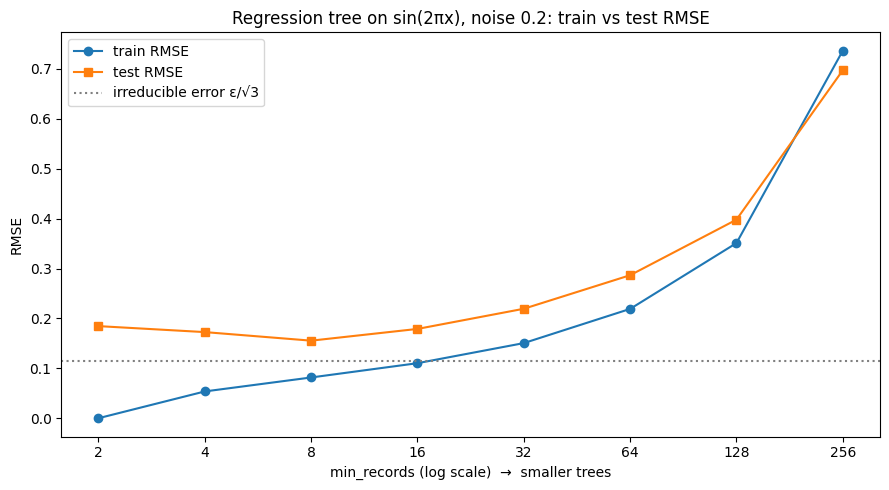

,min_records,leaves,train RMSE,test RMSE
0,2,160,0.0000,0.1845
1,4,84,0.0537,0.1726
2,8,41,0.0816,0.1554
3,16,16,0.1103,0.1789
4,32,10,0.1505,0.2193
5,64,5,0.2191,0.2866
6,128,2,0.3510,0.3979
7,256,1,0.7365,0.6974


In [19]:
f_sin = lambda x: np.sin(2 * np.pi * x)
X_s, y_s = generate_noisy_dataset(EXTRA_NONE, f_sin, (0, 1), 200, 0.2, seed=123)
Xs_tr, Xs_te, ys_tr, ys_te = split(X_s, y_s)          # 160 train / 40 test

mr_values = [2, 4, 8, 16, 32, 64, 128, 256]
tr_err, te_err, n_leaves = [], [], []
for mr in mr_values:
    t = RegressionTree().fit((Xs_tr, ys_tr), min_records=mr)
    tr_err.append(evaluate_model(t.predict(Xs_tr), ys_tr))
    te_err.append(evaluate_model(t.predict(Xs_te), ys_te))
    n_leaves.append(len(t.leaf_sizes()))

plt.figure(figsize=(9, 5))
plt.plot(mr_values, tr_err, "o-", label="train RMSE")
plt.plot(mr_values, te_err, "s-", label="test RMSE")
plt.axhline(0.2 / np.sqrt(3), color="gray", linestyle=":", label="irreducible error ε/√3")
plt.xscale("log", base=2)
plt.xticks(mr_values, mr_values)
plt.xlabel("min_records (log scale)  →  smaller trees")
plt.ylabel("RMSE")
plt.title("Regression tree on sin(2πx), noise 0.2: train vs test RMSE")
plt.legend()
plt.tight_layout()
plt.show()

pd.DataFrame({"min_records": mr_values, "leaves": n_leaves,
              "train RMSE": np.round(tr_err, 4), "test RMSE": np.round(te_err, 4)})

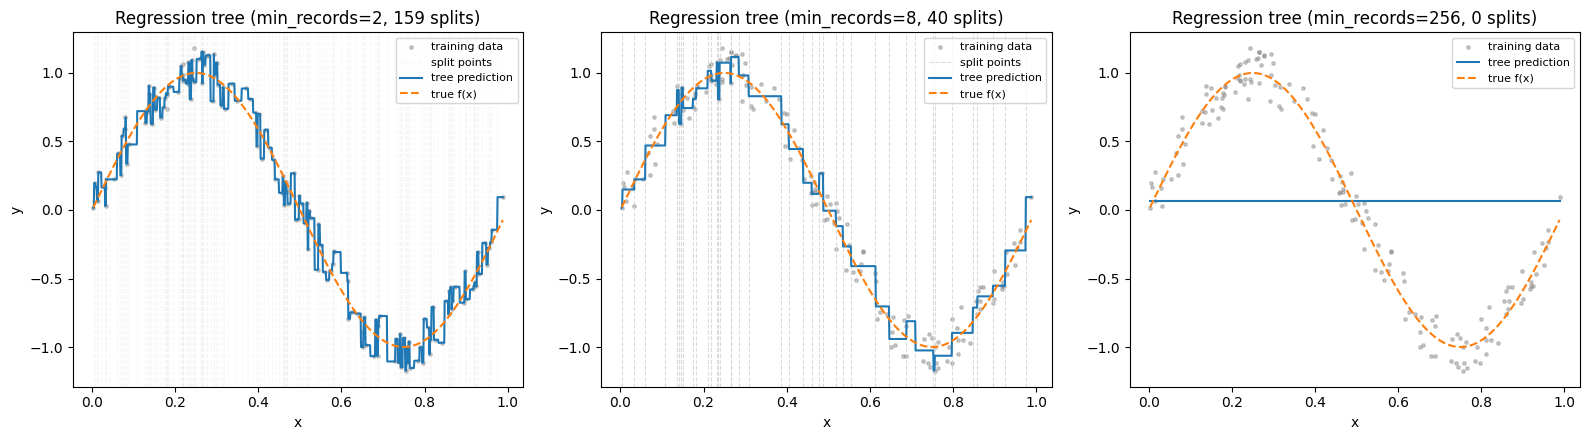

best min_records (lowest test RMSE): 8


In [20]:
# visual check: most complex, best, and simplest trees
best_mr = mr_values[int(np.argmin(te_err))]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, mr in zip(axes, [2, best_mr, 256]):
    RegressionTree().fit((Xs_tr, ys_tr), mr).visualize(true_f=f_sin, ax=ax)
plt.tight_layout()
plt.show()
print("best min_records (lowest test RMSE):", best_mr)

**Findings (Q11):** Here the irreducible error is 0.2/√3 ≈ 0.115. With 200 records, the training set has 160 records and the test set has 40.
- **Best model:** **min_records = 8** has the lowest test RMSE (≈ 0.155, 41 leaves). The values 4 and 16 are close behind. The test set has only 40 records, so the exact minimum is somewhat noisy.
- **Highest bias:** **min_records = 256.** There are fewer than 256 training records, so the tree is a single leaf that predicts the mean of y. Both training and test RMSE are very high (≈ 0.74 / 0.70), and the model ignores x entirely.
- **Highest variance:** **min_records = 2.** It grows until every leaf holds 1 record (160 leaves). Training RMSE is 0, but test RMSE is ≈ 0.18, and the gap between them is the largest. The tree memorized the noise, so a different sample would give a very different tree.

As min_records increases, training RMSE rises steadily (less fitting of the noise), while test RMSE first falls (less variance) and then rises (more bias). This is the U-shape of the bias–variance tradeoff.

## Question 12: Hyper-parameters

**Linear regression:** the algorithm itself has **no tunable hyper-parameters**. `fit` solves the normal equation in closed form, with no learning rate, no number of iterations, and no regularization strength. The only modeling choice is the **input schema**, i.e. which extra columns $f_1(x), \dots, f_d(x)$ are passed to the generator (e.g. x², x³, …). That controls model complexity, as Q7 shows. The intercept is always included.

**Regression tree:** one hyper-parameter, **`min_records`**: a node is split only if it holds at least `min_records` training records. It is a pre-pruning control on tree size. Small values give deep trees (low bias, high variance), and large values give shallow trees (high bias, low variance). Everything else is a fixed design choice, not a parameter: split score = SSE (variance), binary splits at midpoints between consecutive distinct values, leaf prediction = mean, plus the hard stops when all y-values or all x-values in a node are equal. There is no max depth, no minimum leaf size, and no post-pruning.